In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# PCN

In [ ]:
class PCNbaseModel:
    def __init__(self, **kwargs):
        outdim = kwargs.pop("outdim",1)
        p_phidim = kwargs.pop("p_phidim",1)
        num_theta = kwargs.pop("num_theta",1)
        theta = kwargs.pop("theta",1)
        dt = kwargs.pop("dt", 0.01)
        dt_lrn = kwargs.pop("dt_lrn",0.0001)
        root = kwargs.pop("root",False)
        root_p_input = kwargs.pop("root_p_input",1)
        self.learn_step = kwargs.pop("learn_step",20)
        self.infer_step = kwargs.pop("infer_step",40)
        self.node_id = kwargs.pop("node_id","node_id")

        # 초기 추론, 분산
        self.phi = np.ones((outdim,1))
        self.sigma = np.ones((outdim,1))
        # 에러들은 0
        self.e = np.zeros((outdim, 1))
        self.inter_e = np.ones((outdim,1))
        #입력 함수가 비선형
        self.theta = np.random.normal(0, 0.1,(outdim,p_phidim))
        # 시간 간격
        self.dt = dt
        self.dt_lrn = dt_lrn
        # 동역학 변수
        self.d_phi = np.ones((outdim,1))
        self.de = np.ones((outdim,1))
        self.dinter_e = np.ones((outdim,1))
        # 최심층, Root 노드냐?
        self.root = root
        self.p_input = np.ones((outdim,1))

    def f(self, phi):
        return np.tanh(phi)
    def df(self, phi):
        return 1 - np.tanh(phi)**2
    #에러 계산
    def inferenceDynamics(self, u, p_input):
        # inference
        # infer 1단계 예측 오류(Errors) 계산
        self.d_phi = u * self.df(self.phi) - self.e
        if self.root == False:
          self.de = (self.phi - self.theta @ self.f(p_input)) - self.inter_e
          self.dinter_e = self.sigma * self.e - self.inter_e
        else:
          self.de.fill(0)
          self.dinter_e.fill(0)
    #추론 수정
    def updateInference(self):
        # infer 단계 다음 시점 계산
        self.phi = np.clip(self.phi + self.dt * self.d_phi, -100, 100)
        self.e = np.clip(self.e + self.dt * self.de, -100, 100)
        self.inter_e = np.clip(self.inter_e + self.dt * self.dinter_e, -100, 100)
    #시냅스 수정
    def updateSynapse(self, p_input):
        # Learning
        dsigma = self.dt_lrn * (self.e * self.inter_e - 1)
        self.sigma = np.clip(self.sigma + dsigma, 1, 100)
        self.theta = np.clip(self.theta + self.dt_lrn * self.e * self.f(p_input).T, -100, 100)
    def inference_learn(self, u, p_input, learn=True):
        # 인지/추론 단계
        for i in range(self.infer_step):
            self.inferenceDynamics(u=u, p_input = p_input)
            self.updateInference()
        # 학습 단계
        if learn:
            for i in range(self.learn_step):
                self.updateSynapse(p_input)
        # 상위 노드로 에러 전달
        out_u = self.theta.T@self.e
        return self.phi, out_u
    def generate(self,p_input):
        generated = self.theta @ self.f(p_input)
        return generated.copy()

# tPC

In [ ]:
class tPC:
    '''
    F_k = 1/2 * (y_k - C * f(x_k))^2 / sigma_y + 1/2 * (x_k - A * f(X_k-1) - B * u_k)^2 / sigma_x

    e_y = (y_k - C * f(x_k)) / sigma_y
    e_x = (x_k - A * f(x_k-1) - B * u_k) / sigma_x

    dA = dt * e_x * f(x_k-1).T
    dB = dt * e_x * f(x_k).T
    dC = dt * e_y * f(x_k).T

    dx = dt/tau * (-e_x + f'(x_k) * C.T * e_y)
    '''
    def __init__(self, **kwargs):
        dim_y = kwargs.pop("dim_y",1)
        dim_x = kwargs.pop("dim_x",1)
        dim_u = kwargs.pop("dim_u",1)

        self.dt = kwargs.pop("dt", 0.01)
        self.dt_lrn = kwargs.pop("dt_lrn",0.0001)
        self.tau = kwargs.pop("tau", 1)
        self.learn_step = kwargs.pop("learn_step",1)
        self.infer_step = kwargs.pop("infer_step",2)

        self.y = np.zeros((dim_y,1))
        self.x = np.zeros((dim_x,1))
        self.x_prev = np.zeros((dim_x,1))

        self.dx = np.ones((dim_x,1))

        self.A = np.random.normal(0,0.1,(dim_x, dim_x))
        self.B = np.random.normal(0,1, (dim_x, dim_u))
        self.C = np.random.normal(0,1, (dim_y, dim_x))

        self.e_y = np.zeros((dim_y,1))
        self.inter_e_y = np.zeros((dim_y,1))
        self.e_x = np.zeros((dim_x,1))
        self.inter_e_x = np.zeros((dim_x,1))

        self.sigma_y_x = np.ones((dim_y,1))
        self.sigma_x_x_1 = np.ones((dim_x,1))

    def f(self, phi):
        return np.tanh(phi)

    def df(self, phi):
        return 1 - np.tanh(phi)**2
    def inference_learn(self, y, u):
        mu_x = self.A @ self.f(self.x_prev) + self.B @ u
        self.x = mu_x.copy()

        self.e_x[:] = 0
        self.inter_e_x[:] = 0
        self.e_y[:] = 0
        self.inter_e_y[:] = 0

        for i in range(self.infer_step):
            self.inference(y, u)
        for i in range(self.learn_step):
            self.updateSynapse(u)

        self.x_prev = mu_x.copy()
        self.y = self.C @ self.f(self.x)
        return self.y, self.x, self.x_prev

    def inference(self, y, u):
        '''
        self.e_y = np.clip((y - self.C @ self.f(self.x)) / self.sigma_y, -10, 10)
        self.e_x = np.clip((self.x - self.A @ self.f(prev_x) - self.B @ u) / self.sigma_x, -10, 10)
        '''

        de_y = (y - self.C @ self.f(self.x)) - self.inter_e_y
        self.e_y = np.clip(self.e_y + self.dt * de_y, -10, 10)
        dinter_e_y = self.sigma_y_x * self.e_y - self.inter_e_y
        self.inter_e_y = np.clip(self.inter_e_y + self.dt * dinter_e_y, -10, 10)

        de_x = (self.x - self.A @ self.f(self.x_prev) - self.B @ u) - self.inter_e_x
        self.e_x = np.clip(self.e_x + self.dt * de_x, -10, 10)

        dinter_e_x = self.sigma_x_x_1 * self.e_x - self.inter_e_x
        self.inter_e_x = np.clip(self.inter_e_x + self.dt * dinter_e_x, -10, 10)

        self.dx = self.df(self.x) * self.C.T @ self.e_y - self.e_x
        self.x = np.clip(self.x + self.dt/self.tau * self.dx, -10, 10)

    def updateSynapse(self, u):
        dA = self.dt_lrn * self.e_x @ self.f(self.x_prev).T
        dB = self.dt_lrn * self.e_x @ u.T
        dC = self.dt_lrn * self.e_y @ self.f(self.x).T

        self.A = np.clip(self.A + dA, -10, 10)
        self.B = np.clip(self.B + dB, -10, 10)
        self.C = np.clip(self.C + dC, -10, 10)

        '''
        self.sigma_y = np.clip(self.sigma_y + self.dt_lrn*(self.e_y.T @ self.e_y - 1/self.sigma_y)/2, 1, 10)
        self.sigma_x = np.clip(self.sigma_x + self.dt_lrn*(self.e_x.T @ self.e_x - 1/self.sigma_x)/2, 1, 10)
        '''
        dsigma_y = self.dt_lrn * (self.e_y * self.inter_e_y - 1)
        self.sigma_y_x = np.clip(self.sigma_y_x + dsigma_y, 1, 10)
        dsigma_x = self.dt_lrn * (self.e_x * self.inter_e_x - 1)
        self.sigma_x_x_1 = np.clip(self.sigma_x_x_1 + dsigma_x,1, 10)
    def reset(self):
        self.x_prev[:] = 0
    def generate_next_observ(self, x, u):
        next_x = self.generate_next_state(x, u)
        next_observ = self.generate_observ(next_x)
        return next_x, next_observ
    def generate_next_state(self,x, u):
        next_x = self.A @ self.f(x) + self.B @ u
        return next_x
    def generate_observ(self,x):
        observ = self.C @ self.f(x)
        return observ

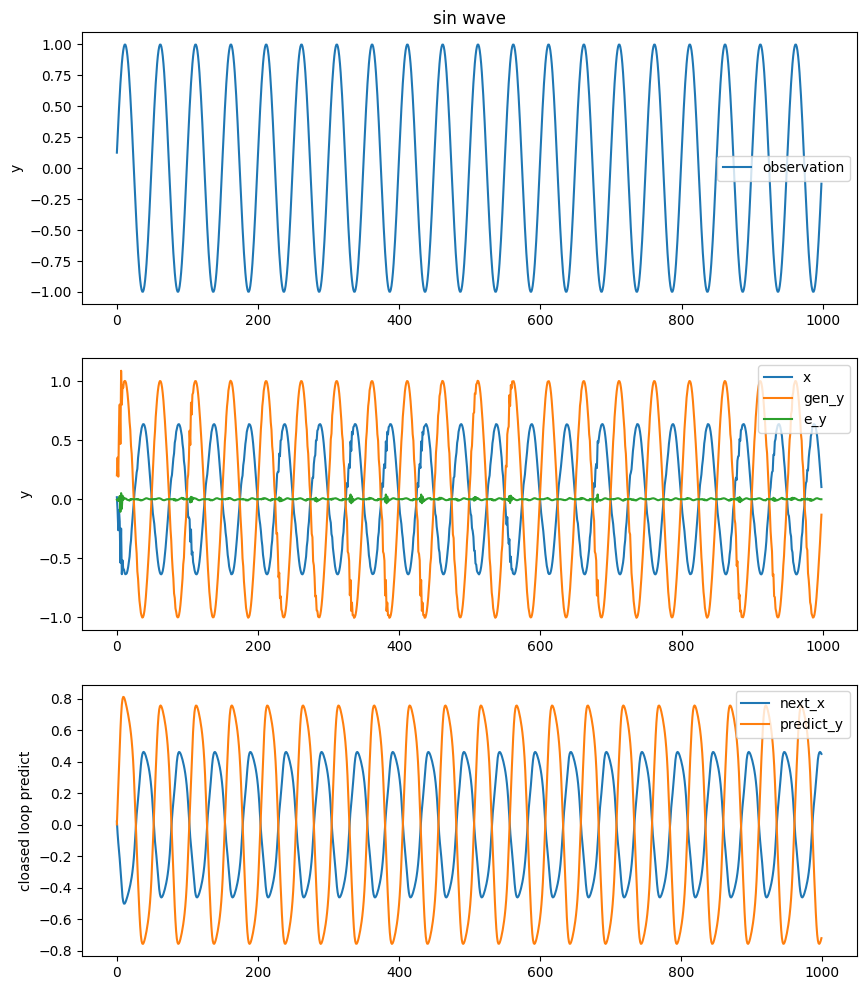

In [ ]:
np.random.seed(0)
test_model = tPC(dim_y=1, dim_x=16, dim_u=1, dt=0.1, dt_lrn=0.01, infer_step=20)

x_list = []
gen_y_list = []
predict_y_list = []
y_list = []
e_y_list = []

#---------
y = np.sin(2*np.pi*np.arange(1000)/50)
# 합성 파동
y_mix = y
#---------
for ep in range(80):
    test_model.reset()
    # (5) scheduled sampling: 자기 예측을 입력으로 쓸 확률을 점진 증가
    p_self = 0.0 if ep < 15 else min(0.9, 0.9*(ep-15)/40)
    errs, prev_pred = [], y_mix[0]

    for idx, current_state in enumerate(y_mix[1:], start=1):
        y = np.array([[current_state]])
        u_val = prev_pred if np.random.rand() < p_self else y_mix[idx-1]
        u = np.array([[u_val]])
        gen_y, gen_x, gen_prev_x = test_model.inference_learn(y, u)
        prev_pred = gen_y[0][0]
        if ep == 79:
          x_list.append(gen_x[0][0])
          e_y_list.append(test_model.e_y[0][0])
          y_list.append(y[0][0])
          gen_y_list.append(gen_y[0][0])

next_x_list = []
x = test_model.x
u = np.array([[y_mix[-1]]])
for i in range(1000):
    next_x, predict_y = test_model.generate_next_observ(x, u)
    x = next_x
    u = predict_y
    # 학습된 모델을 통해 최종 생성된 y값 계산 및 기록
    next_x_list.append(next_x[0][0])
    predict_y_list.append(predict_y[0][0])

plt.figure(figsize=(10,12))
plt.subplot(3,1,1)
plt.plot(y_list, label="observation")
plt.ylabel("y")
plt.legend()
plt.title(f"sin wave")

plt.subplot(3,1,2)
plt.plot(x_list, label="x")
plt.plot(gen_y_list, label="gen_y")
plt.plot(e_y_list, label="e_y")
plt.ylabel("y")
plt.legend()

plt.subplot(3,1,3)
plt.plot(next_x_list, label="next_x")
plt.plot(predict_y_list, label="predict_y")
plt.ylabel("cloased loop predict")
plt.legend()

plt.show()

# Bogaz style tPC RTRL

In [ ]:
class Bogaz_tPC:
    '''
    F_k = 1/2 * (y_k - C * f(x_k))^2 / sigma_y + 1/2 * (x_k - A * f(X_k-1) - B * u_k)^2 / sigma_x

    e_y = (y_k - C * f(x_k)) / sigma_y
    e_x = (x_k - A * f(x_k-1) - B * u_k) / sigma_x

    dA = dt * e_x * f(x_k-1).T
    dB = dt * e_x * f(x_k).T
    dC = dt * e_y * f(x_k).T

    dx = dt/tau * (-e_x + f'(x_k) * C.T * e_y)
    '''
    def __init__(self, **kwargs):
        dim_y = kwargs.pop("dim_y",1)
        dim_x = kwargs.pop("dim_x",1)
        dim_u = kwargs.pop("dim_u",1)
        self.learn_step = kwargs.pop("learn_step",1)
        self.infer_step = kwargs.pop("infer_step",2)

        self.dt = kwargs.pop("dt", 0.01)
        self.dt_lrn = kwargs.pop("dt_lrn",0.0001)
        self.tau = kwargs.pop("tau", 1)

        self.y = np.zeros((dim_y,1))
        self.x = np.zeros((dim_x,1))
        self.prev_x = np.ones((dim_x,1))

        self.dx = np.ones((dim_x,1))

        self.M_A = np.zeros((dim_x, dim_x, dim_x))
        self.M_B = np.zeros((dim_x, dim_x, dim_u))

        self.A = np.random.normal(0,0.1, (dim_x, dim_x))
        self.B = np.random.normal(0,1, (dim_x, dim_u))
        self.C = np.random.normal(0,1, (dim_y, dim_x))

        self.e_y = np.zeros((dim_y,1))
        self.inter_e_y = np.zeros((dim_y,1))
        self.e_x = np.zeros((dim_x,1))
        self.inter_e_x = np.zeros((dim_x,1))

        self.sigma_y_x = np.ones((dim_y,1))
        self.sigma_x_x_1 = np.ones((dim_x,1))

    def f(self, phi):
        return np.tanh(phi)

    def df(self, phi):
        return 1 - np.tanh(phi)**2

    def inference_learn(self, y, u):
        mu_x = self.A @ self.f(self.prev_x) + self.B @ u
        self.x = mu_x

        self.e_x[:] = 0
        self.inter_e_x[:] = 0
        self.e_y[:] = 0
        self.inter_e_y[:] = 0

        for i in range(self.infer_step):
            self.inference(y, u)
        for i in range(self.learn_step):
            self.updateSynapse(u)
        self.update_M(u)

        self.prev_x = mu_x
        self.y = self.C @ self.f(self.x)
        return self.y, self.x, self.prev_x

    def inference(self, y, u):

        de_y = (y - self.C @ self.f(self.x)) - self.inter_e_y
        self.e_y = np.clip(self.e_y + self.dt * de_y, -10, 10)
        dinter_e_y = self.sigma_y_x * self.e_y - self.inter_e_y
        self.inter_e_y = np.clip(self.inter_e_y + self.dt * dinter_e_y, -10, 10)

        de_x = (self.x - self.A @ self.f(self.prev_x) - self.B @ u) - self.inter_e_x
        self.e_x = np.clip(self.e_x + self.dt * de_x, -10, 10)

        dinter_e_x = self.sigma_x_x_1 * self.e_x - self.inter_e_x
        self.inter_e_x = np.clip(self.inter_e_x + self.dt * dinter_e_x, -10, 10)

        self.dx = self.df(self.x) * self.C.T @ self.e_y - self.e_x
        self.x = np.clip(self.x + self.dt/self.tau * self.dx, -10, 10)

    def updateSynapse(self, u):
        imadiate_M_A = self.e_x @ self.f(self.prev_x).T
        imadiate_M_B = self.e_x @ u.T
        historic_temp = (self.df(self.prev_x) * self.A.T @ self.e_x)
        historic_M_A = np.einsum('m,mjk->jk', historic_temp.ravel(), self.M_A)
        historic_M_B = np.einsum('m,mjk->jk', historic_temp.ravel(), self.M_B)

        dA = self.dt_lrn * (imadiate_M_A + historic_M_A)
        dB = self.dt_lrn * (imadiate_M_B + historic_M_B)
        dC = self.dt_lrn * self.e_y @ self.f(self.x).T

        self.A = np.clip(self.A + dA, -10, 10)
        self.B = np.clip(self.B + dB, -10, 10)
        self.C = np.clip(self.C + dC, -10, 10)

        '''
        self.sigma_y = np.clip(self.sigma_y + self.dt_lrn*(self.e_y.T @ self.e_y- 1/self.sigma_y)/2, 1, 10)
        self.sigma_x = np.clip(self.sigma_x + self.dt_lrn*(self.e_x.T @ self.e_x- 1/self.sigma_x)/2, 1, 10)
        '''
        dsigma_y = self.dt_lrn * (self.e_y * self.inter_e_y - 1)
        self.sigma_y_x = np.clip(self.sigma_y_x + dsigma_y, 1, 10)
        dsigma_x = self.dt_lrn * (self.e_x * self.inter_e_x - 1)
        self.sigma_x_x_1 = np.clip(self.sigma_x_x_1 + dsigma_x,1, 10)

    def update_M(self, u):
        J = self.A * self.df(self.prev_x).T
        immediate_A = np.einsum('ij,k->ijk', np.eye(self.prev_x.shape[0]), self.f(self.prev_x).ravel())
        immediate_B = np.einsum('ij,k->ijk', np.eye(self.prev_x.shape[0]), u.ravel())
        self.M_A = immediate_A + np.einsum('im,mjk->ijk', J, self.M_A)
        self.M_B = immediate_B + np.einsum('im,mjk->ijk', J, self.M_B)

    def reset(self):
        self.prev_x[:] = 0; self.M_A[:] = 0; self.M_B[:] = 0
    def generate_next_observ(self, x, u):
        next_x = self.generate_next_state(x, u)
        next_observ = self.generate_observ(next_x)
        return next_x, next_observ
    def generate_next_state(self,x, u):
        next_x = self.A @ self.f(x) + self.B @ u
        return next_x
    def generate_observ(self,x):
        observ = self.C @ self.f(x)
        return observ

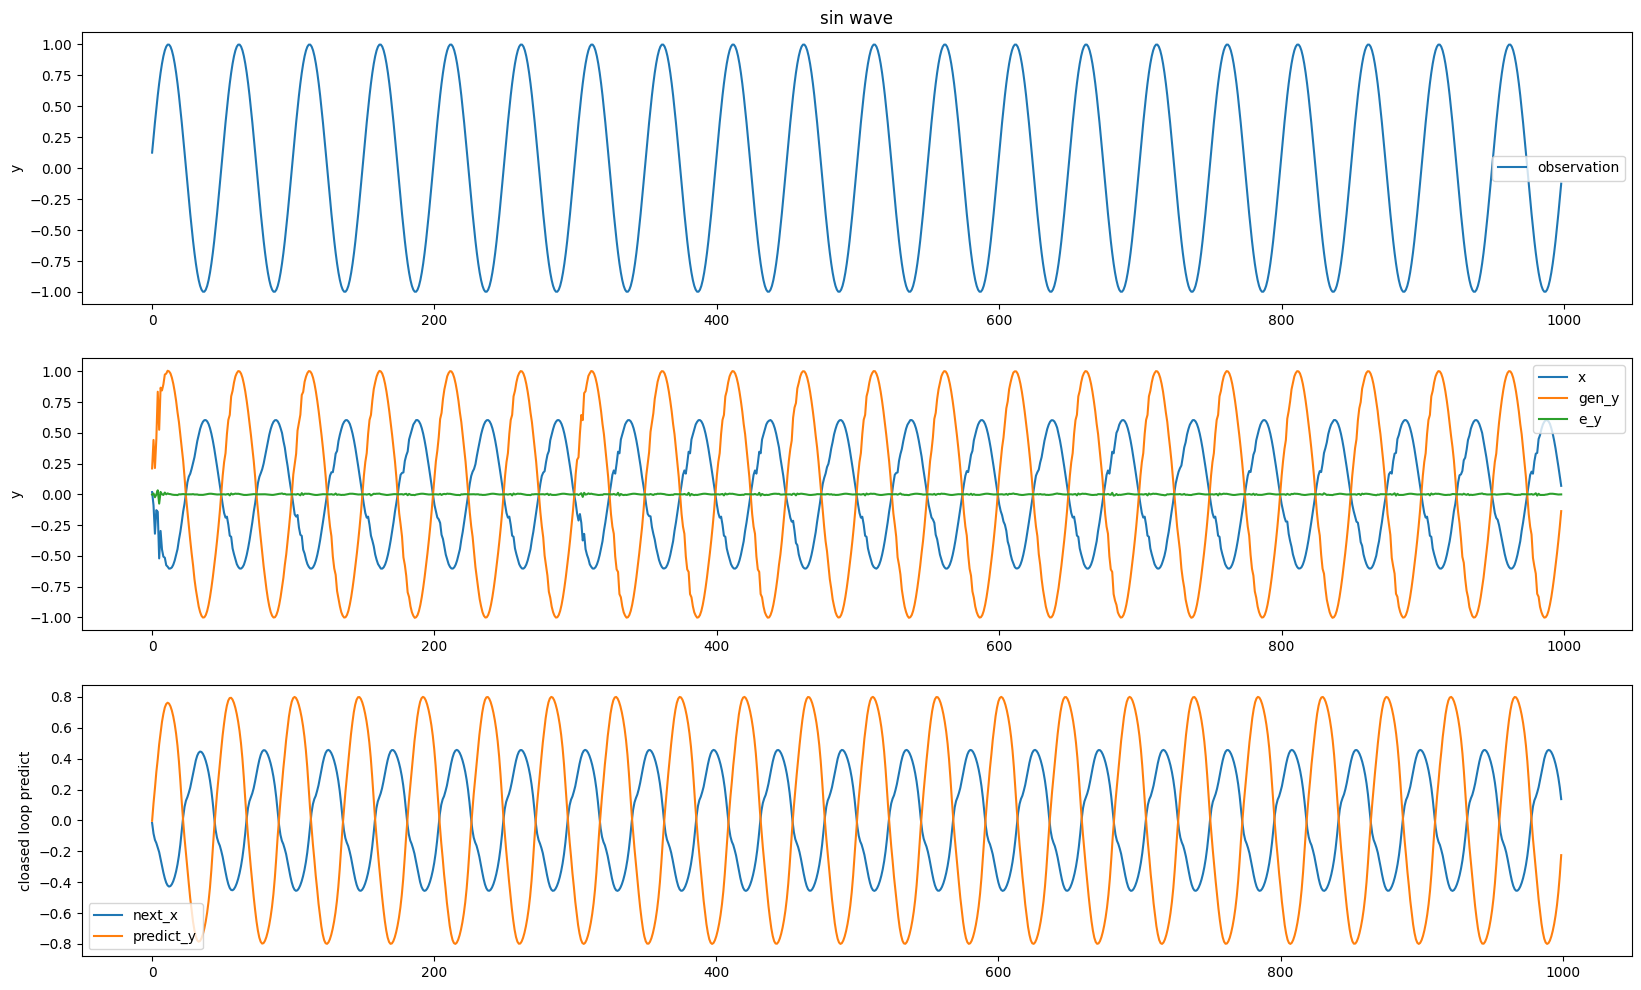

In [ ]:
np.random.seed(0)
test_model = Bogaz_tPC(dim_y=1, dim_x=16, dim_u=1, dt=0.1, dt_lrn=0.01, infer_step=20)

x_list = []
gen_y_list = []
predict_y_list = []
y_list = []
e_y_list = []

#---------
y = np.sin(2*np.pi*np.arange(1000)/50)
# 합성 파동
y_mix = y
#---------
for ep in range(80):
    test_model.reset()
    # (5) scheduled sampling: 자기 예측을 입력으로 쓸 확률을 점진 증가
    p_self = 0.0 if ep < 15 else min(0.9, 0.9*(ep-15)/40)
    errs, prev_pred = [], y_mix[0]

    for idx, current_state in enumerate(y_mix[1:], start=1):
        y = np.array([[current_state]])
        u_val = prev_pred if np.random.rand() < p_self else y_mix[idx-1]
        u = np.array([[u_val]])
        gen_y, gen_x, gen_prev_x = test_model.inference_learn(y, u)
        prev_pred = gen_y[0][0]
        if ep == 79:
          x_list.append(gen_x[0][0])
          e_y_list.append(test_model.e_y[0][0])
          y_list.append(y[0][0])
          gen_y_list.append(gen_y[0][0])

next_x_list = []
x = test_model.x
u = np.array([[y_mix[-1]]])
for i in range(1000):
    next_x, predict_y = test_model.generate_next_observ(x, u)
    x = next_x
    u = predict_y
    # 학습된 모델을 통해 최종 생성된 y값 계산 및 기록
    next_x_list.append(next_x[0][0])
    predict_y_list.append(predict_y[0][0])

plt.figure(figsize=(20,12))
plt.subplot(3,1,1)
plt.plot(y_list, label="observation")
plt.ylabel("y")
plt.legend()
plt.title(f"sin wave")

plt.subplot(3,1,2)
plt.plot(x_list, label="x")
plt.plot(gen_y_list, label="gen_y")
plt.plot(e_y_list, label="e_y")
plt.ylabel("y")
plt.legend()

plt.subplot(3,1,3)
plt.plot(next_x_list, label="next_x")
plt.plot(predict_y_list, label="predict_y")
plt.ylabel("cloased loop predict")
plt.legend()

plt.show()

# tPC-RTRL RG-LRU

In [ ]:
class Precision:
  """대각 정밀도 π. mode로 고정/학습을 스위칭."""
  def __init__(self, dim, mode="fixed", init=1.0, lr=1e-3,
              per_dim=True, ema=0.99, warmup=0):
    assert mode in ("fixed", "grad", "ema")
    self.mode, self.lr, = mode, lr
    self.lo, self.hi = (np.log(init) - 4, np.log(init) + 4)
    self.ema, self.warmup, self.t = ema, warmup, 0
    n = dim if per_dim else 1
    self.log_p = np.full((n, 1), np.log(init))
    self.msq   = np.full((n, 1), 1.0 / init)   # ⟨ε²⟩ 추정치 (ema 모드용)
    self.dim = dim

  @property
  def value(self):                      # 브로드캐스팅으로 (dim,1)에 맞음
    return np.exp(self.log_p)

  def logdet_term(self):                # F에 더해줄 -1/2 Σ log π
    return -0.5 * self.log_p.sum() * (self.dim / len(self.log_p))

  def update(self, e):
    self.t += 1
    if self.mode == "fixed" or self.t <= self.warmup:
        return
    e2 = e**2
    if self.mode == "grad":
        # ∂F/∂λ = (scale/2)(π ε² − 1),  π = exp(λ)  → F에 대한 경사하강
        self.log_p -= self.lr * 0.5 * (self.value * e2 - 1.0)
    else:  # "ema": π = 1/⟨ε²⟩ (F의 정지점 해석해)
        self.msq = self.ema * self.msq + (1 - self.ema) * e2
        self.log_p = -np.log(np.maximum(self.msq, 1e-8))
    np.clip(self.log_p, self.lo, self.hi, out=self.log_p)

In [ ]:
class tPC_RTRL_RGLRU:
  def __init__(self, **kwargs):
    dim_y = kwargs.pop("dim_y",1)
    dim_o = kwargs.pop("dim_o",1)
    dim_x = kwargs.pop("dim_x",1)
    dim_u = kwargs.pop("dim_u",1)
    fixed_c = kwargs.pop("c",8) # 수식 22 상수 c

    # momentum optimizer
    self.momentum = kwargs.pop("momentum", 0.9)
    # adam optimizer
    self.b1 = kwargs.pop("b1", 0.9)
    self.b2 = kwargs.pop("b2", 0.999)
    self.eps = kwargs.pop("eps", 1e-8)
    self.adam_t = 1

    # 수식 22 σ(Λ)^c가 특정 범위(원 논문 기준 0.9~0.999 부근)에 오도록 Λ를 초기화
    self.fixed_c = fixed_c
    u = np.random.rand(dim_x,1) * (0.999 - 0.9) + 0.9
    self.hat = np.log(u**(1/fixed_c) / (1 - u**(1/fixed_c)))
    self.adamhat = np.zeros_like(self.hat)
    self.vhat = np.zeros_like(self.hat)

    self.dt = kwargs.pop("dt", 0.01)
    self.dt_lrn = kwargs.pop("dt_lrn",0.001)
    self.infer_step = kwargs.pop("infer_step",3)
    self.learn_step = kwargs.pop("learn_step",1)

    self.mu_x = np.random.normal(0,0.1,(dim_x,1))
    self.x = np.random.normal(0,0.1,(dim_x,1))
    self.o = np.random.normal(0,0.1,(dim_o,1))
    # momentum
    self.vx = np.zeros((dim_x,1))
    self.vo = np.zeros((dim_o,1))

    self.ga = np.random.normal(0,0.1,(dim_x,1))
    self.gz = np.random.normal(0,0.1,(dim_x,1))
    self.a = np.random.normal(0,0.1,(dim_x,1))
    self.gamma = np.random.normal(0,0.1,(dim_x,1))
    self.p = np.random.normal(0,0.1,(dim_x,1))

    self.wl = np.random.normal(0,0.1,(dim_y,dim_o))
    self.adamwl = np.zeros((dim_y,dim_o))
    self.vwl = np.zeros((dim_y,dim_o))

    self.bl = np.random.normal(0,0.1,(dim_y,1))
    self.adambl = np.zeros((dim_y,1))
    self.vbl = np.zeros((dim_y,1))

    self.wr = np.random.normal(0,0.1,(dim_o,dim_x))
    self.adamwr = np.zeros((dim_o,dim_x))
    self.vwr = np.zeros((dim_o,dim_x))

    self.br = np.random.normal(0,0.1,(dim_o,1))
    self.adambr = np.zeros((dim_o,1))
    self.vbr = np.zeros((dim_o,1))

    self.wa = np.random.normal(0,0.1,(dim_x, dim_u))
    self.adamwa = np.zeros((dim_x, dim_u))
    self.vwa = np.zeros((dim_x, dim_u))

    self.ba = np.random.normal(0,0.1,(dim_x,1))
    self.adamba = np.zeros((dim_x,1))
    self.vba = np.zeros((dim_x,1))

    self.wz = np.random.normal(0,0.1,(dim_x, dim_u))
    self.adamwz = np.zeros((dim_x, dim_u))
    self.vwz = np.zeros((dim_x, dim_u))

    self.bz = np.random.normal(0,0.1,(dim_x,1))
    self.adambz = np.zeros((dim_x,1))
    self.vbz = np.zeros((dim_x,1))

    self.wu = np.random.normal(0,0.1,(dim_x, dim_u))
    self.adamwu = np.zeros((dim_x, dim_u))
    self.vwu = np.zeros((dim_x, dim_u))

    self.bu = np.random.normal(0,0.1,(dim_x,1))
    self.adambu = np.zeros((dim_x,1))
    self.vbu = np.zeros((dim_x,1))

    self.wx0 = np.random.normal(0,0.1,(dim_x, dim_y))
    self.dwx0 = np.zeros((dim_x, dim_y))
    self.adamwx0 = np.zeros((dim_x, dim_y))
    self.vwx0 = np.zeros((dim_x, dim_y))

    self.bx0 = np.random.normal(0,0.1,(dim_x,1))
    self.dbx0 = np.zeros((dim_x,1))
    self.adambx0 = np.zeros((dim_x,1))
    self.vbx0 = np.zeros((dim_x,1))

    self.Mwa = np.zeros((dim_x,dim_u))
    self.Mba = np.zeros((dim_x,1))
    self.Mwz = np.zeros((dim_x,dim_u))
    self.Mbz = np.zeros((dim_x,1))
    self.Mhat = np.zeros((dim_x,1))
    self.Mwu = np.zeros((dim_x,dim_u))
    self.Mbu = np.zeros((dim_x,1))
    self.Mwx0 = np.zeros((dim_x,dim_y))
    self.Mbx0 = np.zeros((dim_x,1))

    self.ex = np.zeros((dim_x,1))
    self.eo = np.zeros((dim_o,1))
    self.ey = np.zeros((dim_y,1))

    # 기본값은 전부 fixed → 기존 동작과 완전히 동일
    pcfg = kwargs.pop("prec_cfg", {})
    def mk(name, dim):
        cfg = {"mode": "fixed", "init": 1.0/dim, "lr": 1e-3}
        cfg.update(pcfg.get(name, {}))
        return Precision(dim, **cfg)

    self.prec = {
        "x":  mk("x", dim_x),
        "o":  mk("o", dim_o),
        "y":  mk("y", dim_y),   # 관측 잡음
        "yg": mk("yg",dim_y),  # 목표 선호
        "u":  mk("u", dim_u),  # 행동 사전
    }

    # 행동리스트
    self.u = np.zeros((dim_u,1))
    self.eu = np.zeros((dim_u,1))

    self.imagine_step = kwargs.pop("imagine_step",30)
    self.dt_act    = kwargs.pop("dt_act", 0.1)

    self.u_list   = [np.zeros((dim_u,1)) for _ in range(self.imagine_step)]  # int 0 → 배열
    self.u_prior  = np.zeros((dim_u,1))
  @property
  def precx(self): return self.prec["x"].value
  @property
  def preco(self): return self.prec["o"].value
  @property
  def precy(self): return self.prec["y"].value
  @property
  def precyg(self): return self.prec["yg"].value
  @property
  def precu(self): return self.prec["u"].value
  def relu(self,x):
    return np.maximum(0,x)
  def relu_derivative(self,x):
    return (x > 0).astype(float)
  def sigmoid(self,x):
    return 1 / (1 + np.exp(-x))
  def sigmoid_derivative(self,x):
    return self.sigmoid(x) * (1 - self.sigmoid(x))
  def tanh(self,x):
    return np.tanh(x)
  def tanh_derivative(self,x):
    return 1 - np.tanh(x)**2
  def inference_learn(self,y,u):
    prev_x = self.x.copy()              # x̄(t-1) 보관
    self.inference_credit(prev_x, u)
    self.x = self.mu_x.copy()           # feedforward 초기화 (2번)
    self.o = self.relu(self.wr @ self.x + self.br)
    # ── Appendix B: feedforward 값 보관 ──
    x_ff = self.x.copy()          # = mu_x
    o_ff = self.o.copy()          # = relu(Wr mu_x + br)
    self.init_errors()
    for _ in range(self.infer_step):
      self.get_errors(y)
      self.inference_static()
    self.get_errors(y)
    self.prec["x"].update(self.ex)
    self.prec["o"].update(self.eo)
    self.prec["y"].update(self.ey)
    for _ in range(self.learn_step):
      self.learn_static(y, x_ff, o_ff)
      self.learn_credit(prev_x, u)
      self.learnt_init()
      self.adam_t += 1

    self.x = self.mu_x.copy()
    predict_y = self.wl @ self.relu(self.wr @ self.x + self.br) + self.bl
    return predict_y.copy(), self.x.copy()

  def inference_static(self):
    drelu_result = self.relu_derivative(self.wr @ self.x + self.br)

    # momentum optimizer 적용
    dx = -((self.ex * self.precx)
          - self.wr.T @ (self.eo * self.preco * drelu_result))
    do = -(self.eo * self.preco
          - self.wl.T @ (self.ey * self.precy))
    self.vx = self.momentum * self.vx + dx
    self.vo = self.momentum * self.vo + do
    self.x += self.dt * self.vx
    self.o += self.dt * self.vo

  def inference_credit(self, prev_x, u):
    self.ga = self.sigmoid(self.wa @ u + self.ba)
    self.gz = self.sigmoid(self.wz @ u + self.bz)
    self.a = np.exp(self.fixed_c * self.ga * np.log(self.sigmoid(self.hat)))
    self.gamma = np.clip((1 - self.a**2)**(1/2), 1e-6, None)
    self.p = self.wu @ u + self.bu

    self.mu_x = self.a * prev_x + self.gamma * (self.gz * self.p)

  def learn_credit(self, prev_x, u):
    # 재료
    da_by_dga = self.a * self.fixed_c * np.log(self.sigmoid(self.hat))
    # 그룹 1 ga 경로 wa, ba
    dmu_x_by_dga = (prev_x - (self.a*self.gz*self.p)/self.gamma) * da_by_dga
    dmu_x_by_dwa = (dmu_x_by_dga * self.ga * (1 - self.ga)) @ u.T
    dmu_x_by_dba = (dmu_x_by_dga * self.ga * (1 - self.ga))

    self.Mwa = self.a * self.Mwa + dmu_x_by_dwa
    self.Mba = self.a * self.Mba + dmu_x_by_dba

    # 그룹2 hat
    dloga_by_dhat = self.fixed_c * self.ga * (1 - self.sigmoid(self.hat))
    dmu_x_by_dloga = prev_x * self.a - (self.gz * self.p * self.a**2)/self.gamma
    dmu_x_by_dhat = dmu_x_by_dloga * dloga_by_dhat

    self.Mhat = self.a * self.Mhat + dmu_x_by_dhat

    # 그룹 3 gz 경로 wz, bz
    dmu_x_by_dgz = self.gamma * self.p
    dmu_x_by_dwz = dmu_x_by_dgz * self.gz * (1 - self.gz) @ u.T
    dmu_x_by_dbz = dmu_x_by_dgz * self.gz * (1 - self.gz)

    self.Mwz = self.a * self.Mwz + dmu_x_by_dwz
    self.Mbz = self.a * self.Mbz + dmu_x_by_dbz

    # 그룹 4 wu, bu projection
    dmu_x_by_dp = self.gamma * self.gz
    dmu_x_by_dwu = dmu_x_by_dp @ u.T

    self.Mwu = self.a * self.Mwu + dmu_x_by_dwu
    self.Mbu = self.a * self.Mbu + dmu_x_by_dp

    grad = (self.ex * self.precx * self.Mwa)
    self.adamwa, self.vwa, dwa = self.adam_optim(self.adamwa, self.vwa, grad)
    self.wa += self.dt_lrn * dwa

    grad = (self.ex * self.precx * self.Mba)
    self.adamba, self.vba, dba = self.adam_optim(self.adamba, self.vba, grad)
    self.ba += self.dt_lrn * dba

    grad = (self.ex * self.precx * self.Mhat)
    self.adamhat, self.vhat, dhat = self.adam_optim(self.adamhat, self.vhat, grad)
    self.hat += self.dt_lrn * dhat

    grad = (self.ex * self.precx * self.Mwz)
    self.adamwz, self.vwz, dwz = self.adam_optim(self.adamwz, self.vwz, grad)
    self.wz += self.dt_lrn * dwz

    grad = (self.ex * self.precx * self.Mbz)
    self.adambz, self.vbz, dbz = self.adam_optim(self.adambz, self.vbz, grad)
    self.bz += self.dt_lrn * dbz

    grad = (self.ex * self.precx * self.Mwu)
    self.adamwu, self.vwu, dwu = self.adam_optim(self.adamwu, self.vwu, grad)
    self.wu += self.dt_lrn * dwu

    grad = (self.ex * self.precx * self.Mbu)
    self.adambu, self.vbu, dbu = self.adam_optim(self.adambu, self.vbu, grad)
    self.bu += self.dt_lrn * dbu

  def adam_optim(self, m,v,g):
    m = self.b1 * m + (1 - self.b1) * g
    v = self.b2 * v + (1 - self.b2) * g**2
    m_hat = m / (1 - self.b1**self.adam_t)
    v_hat = v / (1 - self.b2**self.adam_t)
    adam_grad = (m_hat) / np.sqrt(v_hat + self.eps)
    return m,v,adam_grad
  def learn_static(self, y, x_ff, o_ff):
    eo_fw = self.o - o_ff
    ey_fw = y - (self.wl @ o_ff + self.bl)

    #readout
    drelu_result = self.relu_derivative(self.wr @ x_ff + self.br)
    dwr = ((eo_fw * self.preco * drelu_result) @ x_ff.T)
    dbr = ((eo_fw * self.preco * drelu_result))

    dwl = (ey_fw * self.precy @ o_ff.T)
    dbl = (ey_fw * self.precy)

    self.adamwr, self.vwr, dwr = self.adam_optim(self.adamwr, self.vwr, dwr)
    self.wr += self.dt_lrn * dwr
    self.adambr, self.vbr, dbr = self.adam_optim(self.adambr, self.vbr, dbr)
    self.br += self.dt_lrn * dbr
    self.adamwl, self.vwl, dwl = self.adam_optim(self.adamwl, self.vwl, dwl)
    self.wl += self.dt_lrn * dwl
    self.adambl, self.vbl, dbl = self.adam_optim(self.adambl, self.vbl, dbl)
    self.bl += self.dt_lrn * dbl
  def reset_init(self, x0, s0):
    self.Mwx0 = (1 - x0**2) @ s0.T
    self.Mbx0 = (1 - x0**2)
    self.dwx0[:] = 0
    self.dbx0[:] = 0
  def learnt_init(self):
    self.Mwx0 = self.a * self.Mwx0
    self.Mbx0 = self.a * self.Mbx0

    self.dwx0 += (self.ex * self.precx * self.Mwx0)
    self.dbx0 += (self.ex * self.precx * self.Mbx0)

  def apply_init(self):
    self.adamwx0, self.vwx0, dwx0 = self.adam_optim(self.adamwx0, self.vwx0, self.dwx0)
    self.wx0 += self.dt_lrn * dwx0
    self.adambx0, self.vbx0, dbx0 = self.adam_optim(self.adambx0, self.vbx0, self.dbx0)
    self.bx0 += self.dt_lrn * dbx0

  def get_init(self, s0):
    x0 = self.tanh(self.wx0 @ s0 + self.bx0)
    return x0
  def get_errors(self,y):
    self.ex = self.x - self.mu_x
    self.eo = self.o - self.relu(self.wr @ self.x + self.br)
    self.ey = y - (self.wl @ self.o + self.bl)
  def init_errors(self):
    self.ex[:] = 0;self.eo[:] = 0;self.ey[:] = 0
    self.vx[:] = 0;self.vo[:] = 0
  def get_free_energy(self,y):
    free_energy = ((self.precx * (self.x - self.mu_x)**2).sum()/2
                  + ((self.preco * (self.o - self.relu(self.wr @ self.x + self.br))**2).sum()/2)
                  + ((self.precy * (y - (self.wl @ self.o + self.bl))**2).sum()/2)
                  + self.prec["x"].logdet_term()
                  + self.prec["o"].logdet_term()
                  + self.prec["y"].logdet_term())
    return free_energy
  def reset(self):
    self.x[:] = 0; self.mu_x[:] = 0; self.o[:] = 0
    self.Mwa[:] = 0; self.Mba[:] = 0;
    self.Mwz[:] = 0; self.Mbz[:] = 0; self.Mhat[:] = 0;
    self.Mwu[:] = 0; self.Mbu[:] = 0; self.Mwx0[:] = 0; self.Mbx0[:] = 0;
    self.u_list = [self.u_prior.copy() for _ in range(self.imagine_step)]
    self.u = self.u_prior.copy()

  def future_inference_credit(self, prev_x, u):
    ga = self.sigmoid(self.wa @ u + self.ba)
    gz = self.sigmoid(self.wz @ u + self.bz)
    l = np.log(self.sigmoid(self.hat))
    a = np.exp(self.fixed_c * ga * l)
    gamma = np.clip((1 - a**2)**(1/2), 1e-6, None)
    p = self.wu @ u + self.bu

    mu_x = a * prev_x + gamma * (gz * p)

    alpha_a = self.fixed_c * a * l * ga * (1 - ga)
    alpha_z = gz * (1 - gz)

    J = alpha_a * (prev_x - (gz*p*a)/gamma) * self.wa + (gamma * p * alpha_z) * self.wz + (gamma * gz) * self.wu

    return mu_x, a, J

  def imagine_eps(self, mu_x, y):
    """fixed-prediction 평형해. 반복 없음."""
    pre  = self.wr @ mu_x + self.br
    o_ff = self.relu(pre)
    mask = (pre > 0).astype(float)
    ey   = y - (self.wl @ o_ff + self.bl)
    return self.wr.T @ ((self.wl.T @ (self.precyg * ey)) * mask)

  def imagine(self, target_y):
    K = self.imagine_step
    future_a_list   = [None] * K
    future_eps_list = [None] * K
    future_J_list   = [None] * K
    z               = [None] * K

    x_start = self.x.copy()
    x_prop = x_start.copy()
    for k in range(K):
      mu_x, a, J = self.future_inference_credit(x_prop, self.u_list[k])
      future_a_list[k] = a
      future_eps_list[k] = self.imagine_eps(mu_x, target_y[k])
      future_J_list[k] = J
      x_prop = mu_x.copy()

    z[K-1] = future_eps_list[K-1]

    for s in range(K-2, -1, -1):
      z[s] = future_eps_list[s] + future_a_list[s+1] * z[s+1]
    for s in range(K):
      eu = self.u_list[s] - self.u_prior
      du = future_J_list[s].T @ z[s]  - (eu * self.precu)
      self.u_list[s] += self.dt_act * du

    self.u = self.u_list[0].copy()   # ★ [C] 시프트 전에 꺼낸다
    self.x = x_start.copy()
    return self.u

  def action_plan(self, target_y, n_iter=None):
    for _ in range(n_iter):
      self.imagine(target_y)
    return self.u

  def shift_plan(self):
    """실제로 한 타임스텝 진행한 직후에 호출"""
    self.u_list = [w.copy() for w in self.u_list[1:]] + [self.u_list[-1].copy()]

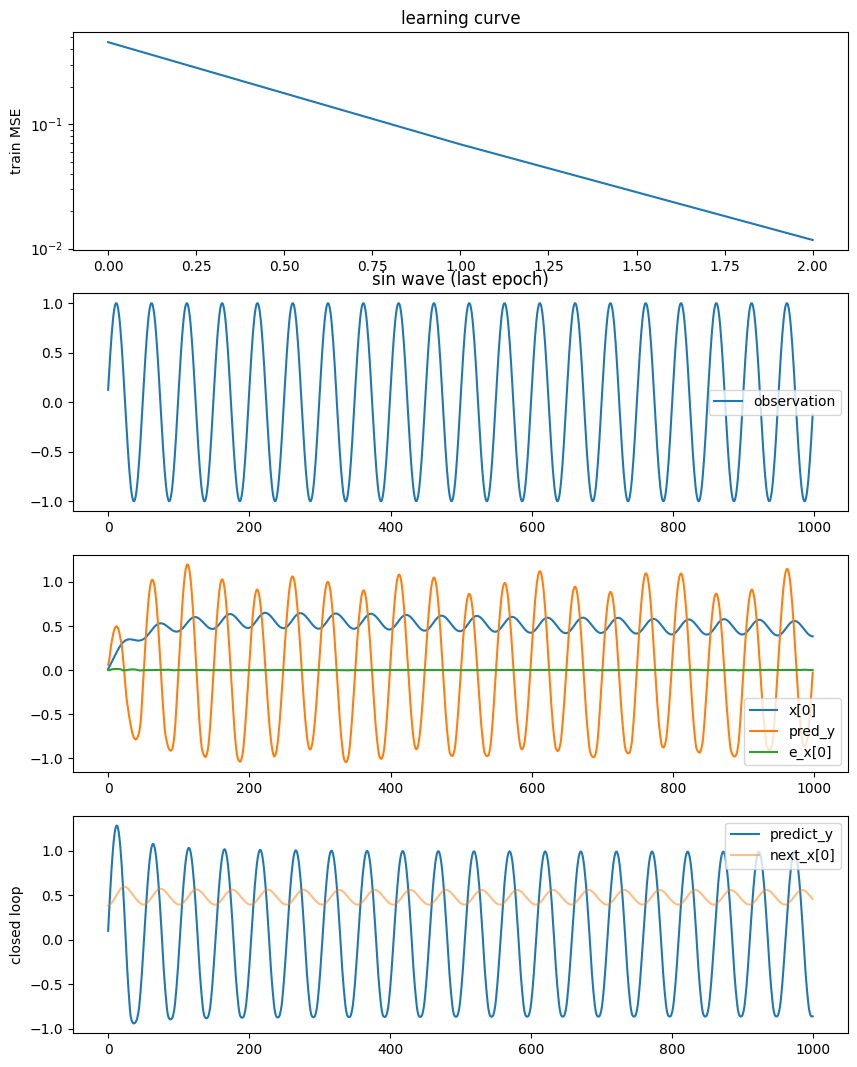

In [ ]:
np.random.seed(0)
BASE  = {}# 항등 고정
test_model = tPC_RTRL_RGLRU(dim_y=1, dim_o=8, dim_x=16, dim_u=1, c=8,
                            dt=1.0, dt_lrn=0.001, infer_step=3, learn_step=1,
                            b1=0.99, b2=0.9999, prec_cfg=BASE)

# ── closed-loop rollout helper: 클래스의 기존 메서드/파라미터만 사용 ──
def rollout_step(model, x, u):
    model.inference_credit(x, u)          # mu_x = f(u, x̄; θ_rec)  (식 20-24)
    next_x = model.mu_x.copy()            # predictive-rollout: x̄ ← μ_x
    o = model.relu(model.wr @ next_x + model.br)
    y = model.wl @ o + model.bl
    return next_x, y

x_list, gen_y_list, y_list, e_x_list, mse_hist = [], [], [], [], []

#---------
y_mix = np.sin(2*np.pi*np.arange(1000)/50)
#---------
n_epoch = 3
for ep in range(n_epoch):
    test_model.reset()
    # scheduled sampling: 자기 예측을 입력으로 쓸 확률을 점진 증가
    p_self = 0.0 if ep < 15 else min(0.9, 0.9*(ep-15)/40)
    prev_pred = y_mix[0]; errs = []

    for idx in range(1, len(y_mix)):
        y = np.array([[y_mix[idx]]])
        u_val = prev_pred if np.random.rand() < p_self else y_mix[idx-1]
        u = np.array([[u_val]])
        pred_y, gen_x = test_model.inference_learn(y, u)
        prev_pred = pred_y[0, 0]
        errs.append((pred_y[0, 0] - y[0, 0])**2)
        if ep == n_epoch - 1:
            x_list.append(gen_x[0, 0])
            e_x_list.append(test_model.ex[0, 0])
            y_list.append(y[0, 0])
            gen_y_list.append(pred_y[0, 0])
    mse_hist.append(np.mean(errs))

# ── closed-loop 생성: 예측 y를 다음 입력 u로 되먹임 ──
predict_y_list, next_x_list = [], []
x = test_model.x.copy()
u = np.array([[y_mix[-1]]])
for i in range(1000):
    x, pred_y = rollout_step(test_model, x, u)
    u = pred_y
    next_x_list.append(x[0, 0])
    predict_y_list.append(pred_y[0, 0])

plt.figure(figsize=(10, 13))
plt.subplot(4, 1, 1)
plt.plot(mse_hist); plt.yscale('log'); plt.ylabel('train MSE'); plt.title('learning curve')
plt.subplot(4, 1, 2)
plt.plot(y_list, label='observation'); plt.legend(); plt.title('sin wave (last epoch)')
plt.subplot(4, 1, 3)
plt.plot(x_list, label='x[0]'); plt.plot(gen_y_list, label='pred_y')
plt.plot(e_x_list, label='e_x[0]'); plt.legend()
plt.subplot(4, 1, 4)
plt.plot(predict_y_list, label='predict_y')
plt.plot(next_x_list, label='next_x[0]', alpha=0.5)
plt.ylabel('closed loop'); plt.legend()
plt.show()

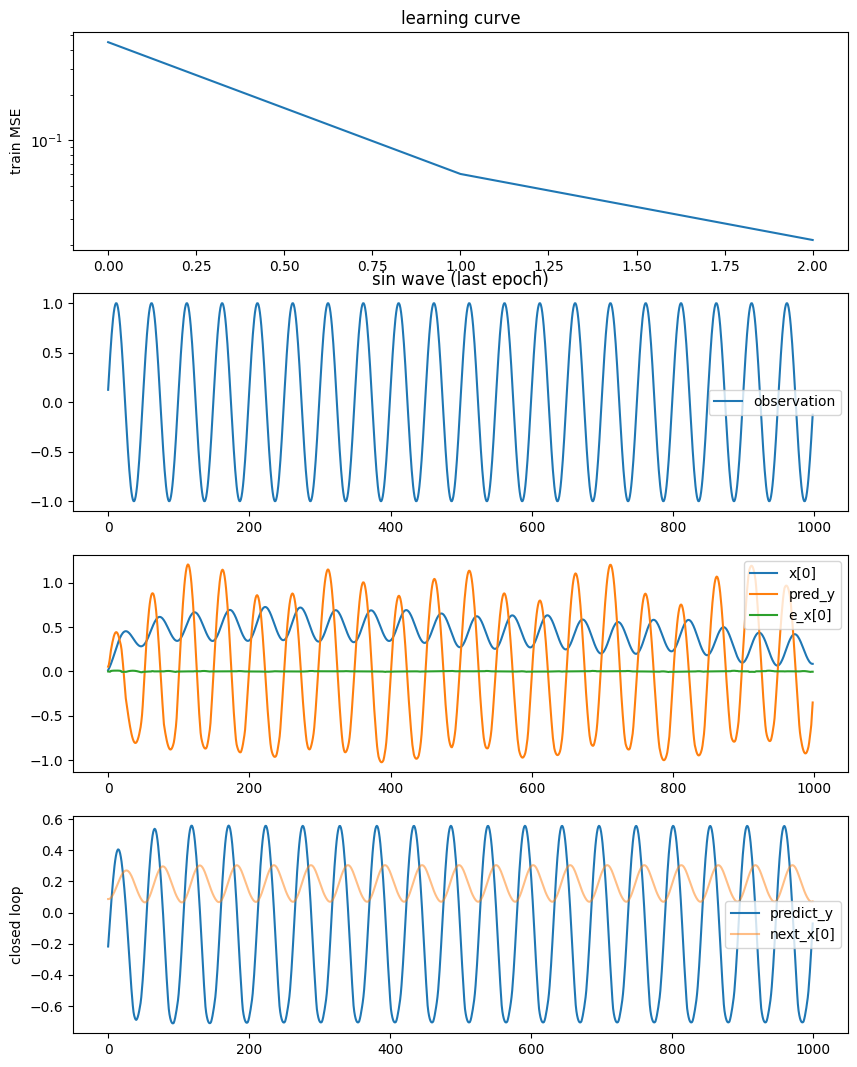

In [ ]:
np.random.seed(0)
LEARN = {k: {"mode": "grad", "lr": 1e-3} for k in "x"}
test_model = tPC_RTRL_RGLRU(dim_y=1, dim_o=8, dim_x=16, dim_u=1, c=8,
                            dt=1.0, dt_lrn=0.001, infer_step=3, learn_step=1,
                            b1=0.99, b2=0.9999, prec_cfg=LEARN)

# ── closed-loop rollout helper: 클래스의 기존 메서드/파라미터만 사용 ──
def rollout_step(model, x, u):
    model.inference_credit(x, u)          # mu_x = f(u, x̄; θ_rec)  (식 20-24)
    next_x = model.mu_x.copy()            # predictive-rollout: x̄ ← μ_x
    o = model.relu(model.wr @ next_x + model.br)
    y = model.wl @ o + model.bl
    return next_x, y

x_list, gen_y_list, y_list, e_x_list, mse_hist = [], [], [], [], []

#---------
y_mix = np.sin(2*np.pi*np.arange(1000)/50)
#---------
n_epoch = 3
for ep in range(n_epoch):
    test_model.reset()
    # scheduled sampling: 자기 예측을 입력으로 쓸 확률을 점진 증가
    p_self = 0.0 if ep < 15 else min(0.9, 0.9*(ep-15)/40)
    prev_pred = y_mix[0]; errs = []

    for idx in range(1, len(y_mix)):
        y = np.array([[y_mix[idx]]])
        u_val = prev_pred if np.random.rand() < p_self else y_mix[idx-1]
        u = np.array([[u_val]])
        pred_y, gen_x = test_model.inference_learn(y, u)
        prev_pred = pred_y[0, 0]
        errs.append((pred_y[0, 0] - y[0, 0])**2)
        if ep == n_epoch - 1:
            x_list.append(gen_x[0, 0])
            e_x_list.append(test_model.ex[0, 0])
            y_list.append(y[0, 0])
            gen_y_list.append(pred_y[0, 0])
    mse_hist.append(np.mean(errs))

# ── closed-loop 생성: 예측 y를 다음 입력 u로 되먹임 ──
predict_y_list, next_x_list = [], []
x = test_model.x.copy()
u = np.array([[y_mix[-1]]])
for i in range(1000):
    x, pred_y = rollout_step(test_model, x, u)
    u = pred_y
    next_x_list.append(x[0, 0])
    predict_y_list.append(pred_y[0, 0])

plt.figure(figsize=(10, 13))
plt.subplot(4, 1, 1)
plt.plot(mse_hist); plt.yscale('log'); plt.ylabel('train MSE'); plt.title('learning curve')
plt.subplot(4, 1, 2)
plt.plot(y_list, label='observation'); plt.legend(); plt.title('sin wave (last epoch)')
plt.subplot(4, 1, 3)
plt.plot(x_list, label='x[0]'); plt.plot(gen_y_list, label='pred_y')
plt.plot(e_x_list, label='e_x[0]'); plt.legend()
plt.subplot(4, 1, 4)
plt.plot(predict_y_list, label='predict_y')
plt.plot(next_x_list, label='next_x[0]', alpha=0.5)
plt.ylabel('closed loop'); plt.legend()
plt.show()

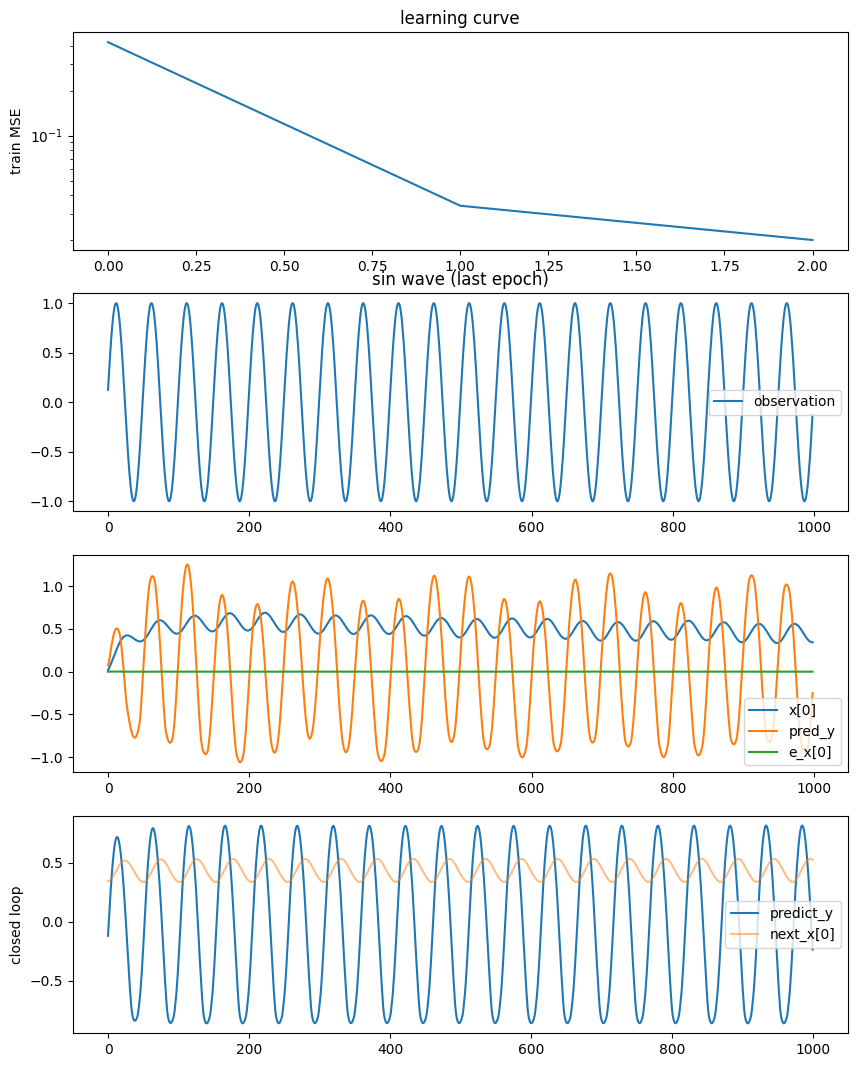

In [ ]:
np.random.seed(0)
LEARN = {k: {"mode": "ema", "lr": 1e-3} for k in "x"}
test_model = tPC_RTRL_RGLRU(dim_y=1, dim_o=8, dim_x=16, dim_u=1, c=8,
                            dt=1.0, dt_lrn=0.001, infer_step=3, learn_step=1,
                            b1=0.99, b2=0.9999, prec_cfg=LEARN)

# ── closed-loop rollout helper: 클래스의 기존 메서드/파라미터만 사용 ──
def rollout_step(model, x, u):
    model.inference_credit(x, u)          # mu_x = f(u, x̄; θ_rec)  (식 20-24)
    next_x = model.mu_x.copy()            # predictive-rollout: x̄ ← μ_x
    o = model.relu(model.wr @ next_x + model.br)
    y = model.wl @ o + model.bl
    return next_x, y

x_list, gen_y_list, y_list, e_x_list, mse_hist = [], [], [], [], []

#---------
y_mix = np.sin(2*np.pi*np.arange(1000)/50)
#---------
n_epoch = 3
for ep in range(n_epoch):
    test_model.reset()
    # scheduled sampling: 자기 예측을 입력으로 쓸 확률을 점진 증가
    p_self = 0.0 if ep < 15 else min(0.9, 0.9*(ep-15)/40)
    prev_pred = y_mix[0]; errs = []

    for idx in range(1, len(y_mix)):
        y = np.array([[y_mix[idx]]])
        u_val = prev_pred if np.random.rand() < p_self else y_mix[idx-1]
        u = np.array([[u_val]])
        pred_y, gen_x = test_model.inference_learn(y, u)
        prev_pred = pred_y[0, 0]
        errs.append((pred_y[0, 0] - y[0, 0])**2)
        if ep == n_epoch - 1:
            x_list.append(gen_x[0, 0])
            e_x_list.append(test_model.ex[0, 0])
            y_list.append(y[0, 0])
            gen_y_list.append(pred_y[0, 0])
    mse_hist.append(np.mean(errs))

# ── closed-loop 생성: 예측 y를 다음 입력 u로 되먹임 ──
predict_y_list, next_x_list = [], []
x = test_model.x.copy()
u = np.array([[y_mix[-1]]])
for i in range(1000):
    x, pred_y = rollout_step(test_model, x, u)
    u = pred_y
    next_x_list.append(x[0, 0])
    predict_y_list.append(pred_y[0, 0])

plt.figure(figsize=(10, 13))
plt.subplot(4, 1, 1)
plt.plot(mse_hist); plt.yscale('log'); plt.ylabel('train MSE'); plt.title('learning curve')
plt.subplot(4, 1, 2)
plt.plot(y_list, label='observation'); plt.legend(); plt.title('sin wave (last epoch)')
plt.subplot(4, 1, 3)
plt.plot(x_list, label='x[0]'); plt.plot(gen_y_list, label='pred_y')
plt.plot(e_x_list, label='e_x[0]'); plt.legend()
plt.subplot(4, 1, 4)
plt.plot(predict_y_list, label='predict_y')
plt.plot(next_x_list, label='next_x[0]', alpha=0.5)
plt.ylabel('closed loop'); plt.legend()
plt.show()